In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

## self-diffusion coefficient in a lattice gas model

In [2]:
def monte_carlo_diffusion(L=50, Np=100, Nsteps=1000, dt=1.0):
    """
    Simulazione Monte Carlo di diffusione su reticolo (Kai Nordlund).
    
    Parametri:
    - L: lato della griglia (L x L)
    - Np: numero di particelle
    - Nsteps: numero di passi Monte Carlo
    - dt: incremento temporale per passo
    """
    # Passo 1 & 2: Inizializzazione della griglia L x L vuota (0 = vuoto, 1 = occupato)
    grid = np.zeros((L, L), dtype=int)
    
    # Memorizza le coordinate correnti delle particelle (x, y)
    particles = np.zeros((Np, 2), dtype=int)
    
    # Spostamenti cumulativi (dx, dy) senza considerare le condizioni al contorno periodiche (Passo 9)
    cumulative_dx = np.zeros(Np, dtype=float)
    cumulative_dy = np.zeros(Np, dtype=float)
    
    # Passo 3a & 3b: Genera Np coordinate casuali senza sovrapposizioni e marca la griglia
    placed = 0
    while placed < Np:
        x = np.random.randint(0, L)
        y = np.random.randint(0, L)
        if grid[x, y] == 0:
            grid[x, y] = 1
            particles[placed] = [x, y]
            placed += 1
            
    # Direzioni possibili di movimento (Su, Giù, Sinistra, Destra)
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    
    # Lista per memorizzare il MSD <R^2> ad ogni istante
    msd_time = []
    t = 0.0
    
    # Passo 4: Loop sui passi MC (tempo)
    for step in range(Nsteps):
        # Passo 5: Loop da 1 a Np (tentativi di movimento per ogni particella in media)
        for _ in range(Np):
            # Passo 6: Scegli una particella i a caso
            i = np.random.randint(0, Np)
            xi, yi = particles[i]
            
            # Passo 7: Trova le posizioni libere in cui può saltare (adiacenti vuote)
            valid_moves = []
            for dx, dy in directions:
                # Calcola le coordinate con condizioni al contorno periodiche per il controllo
                nx = (xi + dx) % L
                ny = (yi + dy) % L
                if grid[nx, ny] == 0:
                    valid_moves.append((dx, dy, nx, ny))
            
            # Se non ci sono posizioni libere, salta (torna al passo 6)
            if not valid_moves:
                continue
            
            # Scegli una direzione valida a caso tra quelle disponibili
            dx, dy, nx, ny = valid_moves[np.random.randint(0, len(valid_moves))]
            
            # Aggiorna la griglia
            grid[xi, yi] = 0
            grid[nx, ny] = 1
            
            # Passo 8: Muovi la particella applicando le condizioni periodiche
            particles[i] = [nx, ny]
            
            # Passo 9: Aggiorna lo spostamento cumulativo SENZA bordi periodici 
            # (usiamo dx e dy del singolo passo elementare [-1, 0, 1])
            cumulative_dx[i] += dx
            cumulative_dy[i] += dy
            
        # Passo 11: Aggiorna il tempo
        t += dt
        
        # Passo 13 (parziale): Calcola <R^2> = <dx^2 + dy^2> al tempo t
        msd = np.mean(cumulative_dx**2 + cumulative_dy**2)
        msd_time.append(msd)
        
    return np.array(msd_time), t

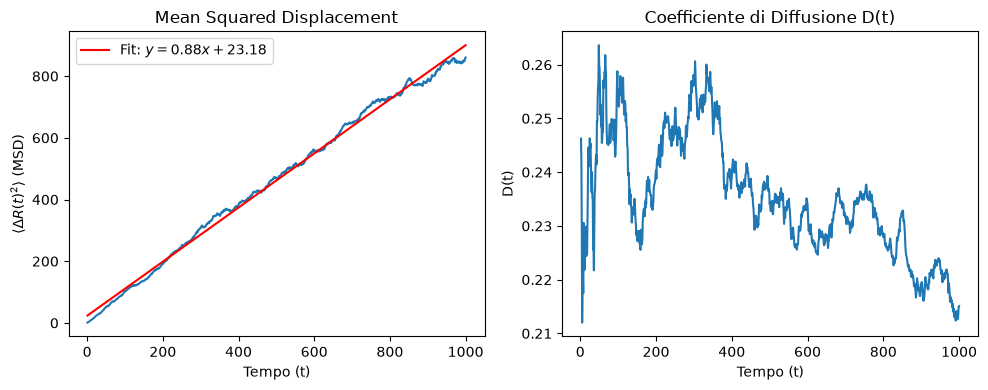

In [3]:
# Esecuzione della simulazione
L = 40
Np = 200
Nsteps = 1000
dt = 1.0

msd, total_time = monte_carlo_diffusion(L, Np, Nsteps, dt)

# Calcolo del coefficiente di diffusione D(t) basato sulla formula fornita:
# D(t) = <R^2> / (2 * d * t) dove d = 2 (dimensione spaziale)
times = np.arange(1, Nsteps + 1) * dt
dimension = 2
D_t = msd / (2 * dimension * times)

#fit del mean squared displacement
m, b = np.polyfit(times, msd, deg=1)

# Visualizzazione dei risultati
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(times, msd)
x_line = np.linspace(min(times), max(times), 100)
y_line = m * x_line + b
plt.plot(
    x_line, y_line, color="red", label=f"Fit: $y = {m:.2f}x {b:+.2f}$"
)
plt.xlabel("Tempo (t)")
plt.ylabel(r"$\langle \Delta R(t)^2 \rangle$ (MSD)")
plt.title("Mean Squared Displacement")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(times[1:], D_t[1:])
plt.xlabel("Tempo (t)")
plt.ylabel("D(t)")
plt.title("Coefficiente di Diffusione D(t)")

plt.tight_layout()
plt.show()

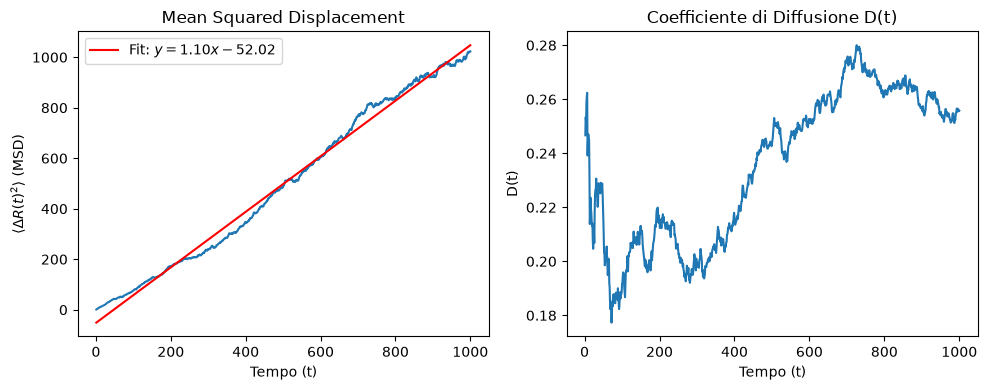

In [4]:
# Esecuzione della simulazione
L = 40
Np = 150
Nsteps = 1000
dt = 1.0

msd, total_time = monte_carlo_diffusion(L, Np, Nsteps, dt)

# Calcolo del coefficiente di diffusione D(t) basato sulla formula fornita:
# D(t) = <R^2> / (2 * d * t) dove d = 2 (dimensione spaziale)
times = np.arange(1, Nsteps + 1) * dt
dimension = 2
D_t = msd / (2 * dimension * times)

#fit del mean squared displacement
m, b = np.polyfit(times, msd, deg=1)

# Visualizzazione dei risultati
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(times, msd)
x_line = np.linspace(min(times), max(times), 100)
y_line = m * x_line + b
plt.plot(
    x_line, y_line, color="red", label=f"Fit: $y = {m:.2f}x {b:+.2f}$"
)
plt.xlabel("Tempo (t)")
plt.ylabel(r"$\langle \Delta R(t)^2 \rangle$ (MSD)")
plt.title("Mean Squared Displacement")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(times[1:], D_t[1:])
plt.xlabel("Tempo (t)")
plt.ylabel("D(t)")
plt.title("Coefficiente di Diffusione D(t)")

plt.tight_layout()
plt.show()